# AI Roles and How AI Work Gets Done

> **Who is this for?** You can already build a small AI feature (a prompt, a RAG pipeline, a simple agent). Now you want to understand **who does what** when an AI system is built and deployed for real users inside a company: which roles exist, what each one does day to day, how they hand work to each other, and which skills each one uses.
>
> **What you will learn:**
> - what 15 common AI roles do day to day, explained simply: forward deployed engineer, deployment strategist, applied AI engineer, LLM engineer, ML engineer, MLOps / LLMOps / ML platform engineer, AI infrastructure / inference engineer, evals engineer, solutions architect, solutions / sales engineer, AI deployment / implementation engineer, AI product engineer, AI product manager, technical account manager / customer engineer, research engineer / applied scientist
> - how to tell similar-sounding roles apart (tables)
> - how these roles work together across the life of one deployment, written as a **RACI responsibility matrix** that we build and check with pandas
> - a **skills map** for every role, where each skill links to the notebook in this repo that teaches it (built and link-checked in code)
> - how to **stay current** with fast-moving models and techniques using a small personal learning system
> - how to build a **portfolio of deployed projects** and how to tell project stories clearly with the **STAR** structure (worked examples)
>
> **Prerequisites:** none strictly. It helps to have seen [How LLMs work](../08_LLM/00_start_here_how_llms_work.ipynb), [AI system design for LLM applications](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) and [Building and shipping an AI feature](../23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb).
>
> **Time needed:** about 2 to 2.5 hours.
>
> **Runs on:** CPU, no API key, no internet. Only pandas, numpy, matplotlib and the standard library. All people, companies and numbers are made up for teaching.

## Explained simply

Building an AI system for a company is like **building and opening a new hospital wing**. Some people talk to the doctors and nurses to learn how they really work (discovery). Some draw the plans (architects). Some build the rooms and connect the water and power to the old building (engineers who integrate). Some make sure the machines are fast and never stop (infrastructure). Some test that everything is safe before patients arrive (evaluation and security). Some train the staff and check that they actually use the new rooms (adoption). And someone decides what to build next and why (product management).

AI work is the same. **Role titles differ between companies**, but the *kinds of work* are stable. If you understand the kinds of work, any job title becomes easy to read: you just ask "which of these kinds of work does this person do most?"

**Tiny example.** A bank wants an assistant that drafts answers for its support agents.
- The **solutions architect** checks early that the idea fits the bank's systems and security rules.
- The **forward deployed engineer** sits with support agents, finds the data, builds a prototype inside the bank's environment and connects it to the ticketing system.
- The **deployment strategist** agrees on success criteria with the head of support and trains the agents.
- The **evals engineer** helps build a test set from 300 real past tickets.
- The **MLOps engineer** sets up monitoring and safe releases.
- The **AI product manager** at the AI company reads the forward deployed engineer's field report and decides that "draft with citations" should become a standard product feature.

| Kind of work | Simple meaning | Roles that do most of it |
|---|---|---|
| Discovery and scoping | Find the real problem, the users, the data and what "success" means | Forward deployed engineer, deployment strategist, solutions architect |
| Building the AI feature | Prompts, retrieval, agents, tools, UI, integrations | Applied AI engineer, LLM engineer, AI product engineer, forward deployed engineer |
| Models | Training, fine-tuning, research on better methods | ML engineer, research engineer / applied scientist |
| Platform and infrastructure | Pipelines, serving, monitoring, GPUs, speed and cost | MLOps / LLMOps / platform engineer, AI infrastructure / inference engineer |
| Quality and safety | Test sets, graders, release gates | Evals engineer (everyone shares it) |
| Rollout and adoption | Installation, training users, support after launch | Implementation engineer, deployment strategist, technical account manager |
| Commercial and product | Pre-sales, deal support, what to build next | Solutions / sales engineer, AI product manager, technical account manager |

### Table of contents
0. Setup
1. Why there are so many AI role names
2. The roles one by one (what they do day to day)
3. Telling similar roles apart
4. How the roles work together on one deployment (the RACI matrix)
5. Skills maps: each role linked to the notebooks that teach its skills
6. Staying current: a personal learning system
7. Building a portfolio of deployed projects
8. Telling project stories with STAR (worked examples)
9. Recap, interview questions and further reading

---
## 0. Setup

We use pandas for tables, matplotlib for two small charts, and a fixed random seed so every run prints the same numbers. `REPO` is the folder above this notebook; we use it to check that every link in the skills maps points to a real notebook.

In [1]:
import os, re, textwrap
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 7
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 30)

# This notebook lives in 28_Applied_AI_and_Forward_Deployed_Engineering/, so the repo root is one level up.
REPO = os.path.abspath("..")
print("repo root found:", os.path.isdir(os.path.join(REPO, "08_LLM")))  # we never print absolute local paths
print("track folders found:", sum(os.path.isdir(os.path.join(REPO, d)) and d[:2].isdigit() for d in os.listdir(REPO)))

repo root found: True
track folders found: 29


---
## 1. Why there are so many AI role names

**What it is.** A *role* is a bundle of responsibilities. A *job title* is the label one company puts on that bundle. The same bundle can carry different titles: "forward deployed engineer", "deployed engineer", "forward deployed software engineer (FDSE)" and "agent deployment engineer" describe very similar work.

**Simple analogy.** In a restaurant, "chef de partie", "line cook" and "station cook" can mean the same job in different kitchens. You learn more by asking "what do you cook, for whom, and with which tools?" than by reading the title.

**How to read any AI role, in three questions:**
1. **Who is the main "customer" of the work?** An outside company (customer-facing roles), an internal product team (product roles), or other engineers and researchers (platform roles).
2. **How close to the model is the work?** Using models through an API, adapting models (fine-tuning, evals), or building and running models (training, serving, GPUs).
3. **What is the main output?** A deployed solution for one customer, a product feature for many users, a platform, a model, a decision, or a signed agreement.

**When to use this view.** Use it to plan your learning: pick the *kinds of work* you enjoy, then learn the skills for them (section 5). Do not over-fit to one title, because titles change faster than the work.

Below we place every role on two axes: how much of the work is **with customers and users** and how deep it goes **into models and infrastructure**. The positions are rough and illustrative (they differ by company and by person), but they show the shape of the landscape.

In [2]:
# One row per role. The numbers (0 = none, 10 = most of the work) are illustrative judgements, not measurements.
roles = pd.DataFrame([
    # code,  role name,                                   customer-facing, model/infra depth, coding share
    ("FDE",   "Forward deployed engineer (FDE / FDSE)",            8, 5, 7),
    ("DS",    "Deployment strategist / delivery lead",             9, 2, 2),
    ("AIE",   "Applied AI engineer",                               5, 5, 8),
    ("LLME",  "LLM engineer",                                      2, 7, 8),
    ("MLE",   "ML engineer",                                       2, 7, 8),
    ("MLOPS", "MLOps / LLMOps / ML platform engineer",             1, 7, 8),
    ("INF",   "AI infrastructure / inference engineer",            1, 9, 9),
    ("EVAL",  "Evals engineer",                                    3, 6, 7),
    ("SA",    "Solutions architect / applied AI architect",        8, 5, 4),
    ("SE",    "Solutions / sales engineer",                        9, 3, 4),
    ("IMPL",  "AI deployment / implementation engineer",           7, 3, 6),
    ("APE",   "AI product engineer",                               4, 4, 9),
    ("PM",    "AI product manager",                                6, 3, 1),
    ("TAM",   "Technical account manager / customer engineer",     9, 2, 2),
    ("RS",    "Research engineer / applied scientist",             1, 9, 7),
], columns=["code", "role", "customer_facing", "model_infra_depth", "coding_share"])

roles.set_index("code")[["role", "customer_facing", "model_infra_depth", "coding_share"]]

,role,customer_facing,model_infra_depth,coding_share
code,,,,
FDE,Forward deployed engineer (FDE / FDSE),8,5,7
DS,Deployment strategist / delivery lead,9,2,2
AIE,Applied AI engineer,5,5,8
LLME,LLM engineer,2,7,8
MLE,ML engineer,2,7,8
MLOPS,MLOps / LLMOps / ML platform engineer,1,7,8
INF,AI infrastructure / inference engineer,1,9,9
EVAL,Evals engineer,3,6,7
SA,Solutions architect / applied AI architect,8,5,4


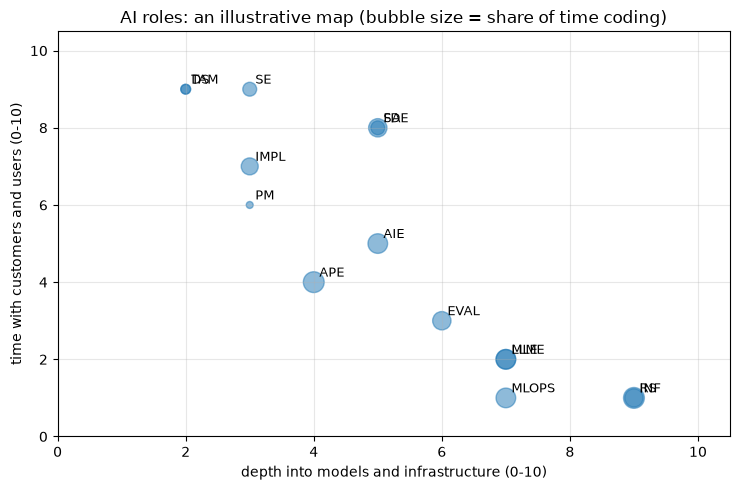

In [3]:
# A simple "role map". Roles near the top-left work mostly with customers; bottom-right mostly with models and machines.
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(roles["model_infra_depth"], roles["customer_facing"], s=roles["coding_share"] * 25, alpha=0.5)
for _, r in roles.iterrows():
    ax.annotate(r["code"], (r["model_infra_depth"], r["customer_facing"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("depth into models and infrastructure (0-10)")
ax.set_ylabel("time with customers and users (0-10)")
ax.set_title("AI roles: an illustrative map (bubble size = share of time coding)")
ax.set_xlim(0, 10.5); ax.set_ylim(0, 10.5); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What just happened?** The chart is a mental map, not data. Three groups stand out:
- **Top-left (customer-facing):** deployment strategist, technical account manager, sales engineer, solutions architect. Their output is mostly decisions, plans, trust and agreements, with some code.
- **Bottom-right (model and infrastructure):** inference engineer, research engineer, ML engineer, MLOps engineer. Their "customers" are other engineers.
- **The middle:** forward deployed engineer, applied AI engineer, evals engineer, AI product engineer. They write a lot of code **and** stay close to users. Many people find this middle band the fastest way to learn the whole picture, because they see every part.

---
## 2. The roles one by one

For each role: **what it is**, a **simple analogy**, **a typical day**, the **main outputs** (the things you can point at when the work is done) and **who they work with most**. A typical day is a mix, not a fixed schedule; it changes with the phase of a project.

### 2.1 Forward deployed engineer (FDE, also FDSE or "deployed engineer")

**What it is.** A software engineer who works *embedded with a customer* to make an AI product solve that customer's real problem in production. Roughly half building, half working with customer teams. The idea comes from Palantir's "forward deployed software engineers", and many AI companies now use it for enterprise deployments (more history in [notebook 02](02_forward_deployed_engineering_in_practice.ipynb)).

**Simple analogy.** A doctor who does house calls: instead of waiting for the patient to describe the problem in a clinic, they visit, see how the patient lives, and treat the real cause there.

**A typical day.**
- Morning: a working session with the customer's support team lead to walk through ten real tickets the assistant got wrong yesterday.
- Late morning: write code. Add a tool that looks up order status in the customer's system; write an eval case for each wrong ticket.
- Afternoon: debug why the connector fails in the customer's network (a proxy blocks one domain); talk to their IT team.
- End of day: send a short written update (what changed, what is blocked, what is next) and add one item to the field report for the product team.

**Main outputs.** A working deployment inside the customer's environment; integrations (APIs, connectors, MCP servers, tools); eval sets and harnesses; runbooks and handoff docs; field reports that turn one customer's needs into product improvements; reusable patterns other deployments can copy.

**Works most with.** Deployment strategist, customer engineers and subject-matter experts, solutions architect, product and research teams back home.

### 2.2 Deployment strategist / deployment lead / delivery lead

**What it is.** The partner of the FDE who owns the **problem and the plan** rather than the code. Finds the most valuable problems, maps workflows, agrees success criteria and baselines, runs the delivery plan (milestones, dependencies, acceptance), leads change management and training, and reports value to executives. Light coding or SQL helps but is not the main job.

**Simple analogy.** The project manager and translator on a construction site: they make sure the builders build what the owners really need, on time, and that people move in and use it.

**A typical day.** A steering meeting with the customer's executive sponsor; a workshop mapping how claims are processed today; updating the value case with this week's numbers; planning a training session for 40 users; unblocking a data-access request.

**Main outputs.** Use-case shortlist and prioritisation, success plan, delivery plan, stakeholder map, training material, adoption reports, value / ROI reports, executive updates.

### 2.3 Applied AI engineer

**What it is.** An engineer who turns model capabilities into working solutions: prompts, retrieval, agents, tool use, evals, and the code around them. In some companies this is a *customer-facing* technical role (helping customers build on the company's models: prototypes, architecture advice, workshops). In others it is a *product team* role that ships AI features. Both share the same core: get reliable behaviour from models in a real system.

**Simple analogy.** A skilled cook who knows exactly how each ingredient (model, retrieval, tools) behaves and combines them into a dish that comes out right every time.

**A typical day.** Run the eval suite on a new prompt version; fix a regression on long documents; add structured outputs to an extraction step; review token cost per request; pair with a customer engineer on their integration.

**Main outputs.** Prompt and agent code, RAG pipelines, eval suites, reference implementations and notebooks or cookbooks, performance and cost reports.

### 2.4 LLM engineer

**What it is.** Similar to the applied AI engineer but closer to the model itself: fine-tuning (for example LoRA), preparing training data, optimising prompts and retrieval at scale, serving open-weight models, and running benchmarks.

**Simple analogy.** A car tuner. The car (the base model) already works; the tuner adjusts it for one kind of road.

**A typical day.** Clean and de-duplicate 20,000 training examples; run a LoRA fine-tune; compare it with the base model plus a better prompt; write up why the cheaper option wins on the eval set.

**Main outputs.** Fine-tuned model variants, training datasets, benchmark results, model-choice recommendations.

### 2.5 Machine learning engineer (ML engineer)

**What it is.** Builds, trains and maintains models in production: classic ML (ranking, fraud, forecasting) and deep learning, plus the data pipelines and retraining around them. With LLMs, ML engineers also train embedding models, classifiers and rerankers that sit next to the LLM.

**Simple analogy.** A mechanic who builds engines and keeps them running for years, not just for one race.

**A typical day.** Investigate a drop in model accuracy; build features in SQL; retrain and compare against the champion model; push the winner through the model registry and a canary release.

**Main outputs.** Trained models, feature pipelines, training code, model cards, monitoring dashboards.

### 2.6 MLOps / LLMOps / ML platform engineer

**What it is.** Builds the **platform** that lets others train, deploy and watch models safely: pipelines, model registry, CI/CD for models, serving, observability, cost controls, often an internal **LLM gateway** (one front door to many model providers with keys, quotas, logging and failover). LLMOps is the same idea for LLM systems: prompt versioning, tracing, eval gates, token budgets.

**Simple analogy.** The airport ground crew and control tower. Pilots (model builders) fly; the crew makes sure every take-off and landing is safe, logged and on schedule.

**A typical day.** Add a new model to the gateway; fix a flaky deployment pipeline; set up an alert when token spend per tenant jumps; help a team move from a notebook to a scheduled pipeline.

**Main outputs.** Pipelines, infrastructure as code, deployment templates, dashboards and alerts, platform docs.

### 2.7 AI infrastructure / inference engineer

**What it is.** Makes models run **fast, cheaply and reliably** on GPUs and other accelerators: batching, caching (including the KV cache), quantisation, speculative decoding, autoscaling, load balancing, and measuring tail latency. Often contributes to serving engines such as vLLM, SGLang or TensorRT-LLM.

**Simple analogy.** The engineer who designs the motorway: more lanes, smarter traffic lights and fewer jams so every car (request) gets through faster.

**A typical day.** Profile why time-to-first-token got worse after a release; test a new quantisation on the correctness eval; tune batch sizes; review a GPU capacity plan.

**Main outputs.** Faster serving stacks, benchmarks, capacity plans, performance dashboards, kernel or engine changes.

### 2.8 Evals engineer (evaluation engineer)

**What it is.** Owns **how quality is measured**: test sets that look like real use, graders (code checks, model-based "LLM-as-judge" graders checked against humans, human review), regression suites, and release gates that run on every prompt, model or agent change.

**Simple analogy.** The examiner who writes a fair exam. If the exam is bad, nobody knows whether the student (the AI system) really learned.

**A typical day.** Turn last week's production failures into new test cases; measure how often the LLM judge agrees with human reviewers; add a slice for non-English tickets; block a release that fails the safety gate.

**Main outputs.** Eval datasets, grader code, dashboards, release-gate rules, eval methodology docs.

### 2.9 Solutions architect / applied AI architect

**What it is.** A senior technical advisor who designs **how the solution fits** the customer's world: models, data, integrations, identity and security, deployment option (cloud, private network, on-premises), evaluation and cost. Active both before a contract (shaping the solution) and after (guiding the build, often with partners).

**Simple analogy.** The architect who draws the plans for an extension so that it joins the old house safely, meets building rules and fits the budget.

**A typical day.** Run an architecture review with the customer's security team; draw a reference architecture for private networking; answer questions on data residency; brief a systems-integrator partner who will build part of it.

**Main outputs.** Architecture diagrams, reference architectures, security review answers, technical sections of proposals, design reviews.

### 2.10 Solutions engineer / sales engineer (pre-sales)

**What it is.** The technical partner of the account executive (the person who owns the commercial relationship) **before** a customer buys: understands requirements, gives tailored demos, runs technical evaluations and proofs of concept, answers technical parts of RFPs (formal requests for proposal), and earns the "technical win" (the customer's technical team agrees the product can do the job).

**Simple analogy.** The test-drive expert at a car dealer who knows the engine and can show the car on the buyer's own daily route.

**A typical day.** A discovery call; build a demo on the prospect's sample data; answer 60 technical questions in a security questionnaire; plan a two-week proof of concept with clear success criteria.

**Main outputs.** Demos, POC plans and results, RFP responses, technical-win summaries, handoff notes for the delivery team.

### 2.11 AI deployment engineer / implementation engineer

**What it is.** Gets a (mostly existing) product **installed, configured and connected** for each customer: setup, single sign-on, data connectors, configuration of agents or workflows, testing and go-live. Compared with an FDE, the work is more repeatable and less custom-built.

**Simple analogy.** The technician who installs and sets up a new kitchen that was designed in the factory: measures, connects water and power, tests every appliance, shows the owner how it works.

**A typical day.** Configure SSO and user provisioning for a new customer; set up a connector to their knowledge base; run the go-live checklist; fix a configuration error found in user acceptance testing.

**Main outputs.** Configured deployments, go-live checklists, configuration docs, issue tickets back to product.

### 2.12 AI product engineer

**What it is.** A full-stack engineer with strong product sense who ships AI features **inside a product** used by many customers: the UI, the backend, the LLM calls, logging and the success metrics. Decides whether a feature needs an LLM at all, or whether rules or classic ML are enough.

**Simple analogy.** A furniture designer-maker: designs the chair for real people, builds it, and watches how people sit on it.

**A typical day.** Build a "suggest reply" button; add streaming and an undo; instrument acceptance rate; look at user sessions where suggestions were ignored; ship a fix behind a feature flag.

**Main outputs.** Shipped features, experiments and their results, product metrics.

### 2.13 AI product manager

**What it is.** Decides **what to build and why**, and what "good" means for an AI feature: the problem, the users, the quality bar (often written as evals), the roadmap, pricing input, and the launch. Balances quality, cost, latency, safety and time.

**Simple analogy.** The head chef who designs the menu: which dishes, for which guests, at what price, and how we know a dish is ready to serve.

**A typical day.** Review eval results with engineering; write a short product spec; read field reports from FDEs; talk to three customers; decide whether a quality gap blocks the launch.

**Main outputs.** Product specs, quality definitions and eval criteria, roadmaps, launch plans, pricing and packaging proposals (more in [notebook 03](03_ai_product_strategy_and_business_skills.ipynb)).

### 2.14 Technical account manager (TAM) / customer engineer

**What it is.** The long-term technical partner of a customer **after** the sale: health checks, escalations, upgrades, usage reviews, planning the next use cases, and making sure the customer gets value over months and years.

**Simple analogy.** The family doctor: not the surgeon who did the operation, but the person who knows your history and keeps you healthy.

**A typical day.** A quarterly business review with usage numbers; chase a support escalation with engineering; plan a model upgrade with the customer; share best practices from similar customers.

**Main outputs.** Account health reports, success plans, escalation records, renewal and expansion input.

### 2.15 Research engineer / applied scientist

**What it is.** Improves the methods and models themselves: post-training (for example RLHF), new eval methods, data pipelines for training, synthetic data, and experiments that show whether an idea really works. *Research engineers* lean towards building the training and experiment infrastructure; *applied scientists* lean towards applying research to one business problem.

**Simple analogy.** The lab that invents a new medicine, as opposed to the hospital that uses it.

**A typical day.** Debug a training run; design an ablation; analyse results with confidence intervals; read papers; write up findings for the team. Rigorous method matters most here (see [24_Research_Methods](../24_Research_Methods/README.md)).

**Main outputs.** Experiments and their write-ups, improved models, new datasets and eval methods, papers or internal reports.

In [4]:
# The same information as a compact table we can reuse later in the notebook.
roles["main_outputs"] = [
    "deployment in customer env, integrations, evals, field reports, playbooks",
    "use-case shortlist, success plan, delivery plan, training, value reports",
    "prompt/agent/RAG code, eval suites, reference implementations",
    "fine-tuned variants, training data, benchmark results",
    "trained models, feature pipelines, monitoring",
    "pipelines, gateway, IaC, deployment templates, dashboards",
    "fast serving stack, benchmarks, capacity plans",
    "eval datasets, graders, release gates",
    "architectures, reference designs, security review answers",
    "demos, POC plans/results, RFP answers, technical win",
    "configured deployments, go-live checklists",
    "shipped features, experiments, product metrics",
    "specs, quality bar/evals, roadmap, launch plan",
    "health reports, escalations, success plans",
    "experiments, improved models, eval methods, write-ups",
]
roles["main_customer_of_the_work"] = [
    "one external customer", "one external customer", "customer or product team", "internal teams",
    "internal teams", "internal engineers", "internal engineers", "internal teams",
    "external customer + partners", "prospective customer", "one external customer", "product users",
    "product users + business", "existing customer", "research / product teams",
]
roles[["code", "role", "main_customer_of_the_work", "main_outputs"]]

,code,role,main_customer_of_the_work,main_outputs
0,FDE,Forward deployed engineer (FDE / FDSE),one external customer,"deployment in customer env, integrations, evals, field reports, playbooks"
1,DS,Deployment strategist / delivery lead,one external customer,"use-case shortlist, success plan, delivery plan, training, value reports"
2,AIE,Applied AI engineer,customer or product team,"prompt/agent/RAG code, eval suites, reference implementations"
3,LLME,LLM engineer,internal teams,"fine-tuned variants, training data, benchmark results"
4,MLE,ML engineer,internal teams,"trained models, feature pipelines, monitoring"
5,MLOPS,MLOps / LLMOps / ML platform engineer,internal engineers,"pipelines, gateway, IaC, deployment templates, dashboards"
6,INF,AI infrastructure / inference engineer,internal engineers,"fast serving stack, benchmarks, capacity plans"
7,EVAL,Evals engineer,internal teams,"eval datasets, graders, release gates"
8,SA,Solutions architect / applied AI architect,external customer + partners,"architectures, reference designs, security review answers"
9,SE,Solutions / sales engineer,prospective customer,"demos, POC plans/results, RFP answers, technical win"


---
## 3. Telling similar roles apart

Several roles sound alike. The quickest way to separate them is to ask **when** in the customer's journey they work, **how custom** the work is, and **what they hand over**.

### Customer-facing technical roles

| | Solutions / sales engineer | Solutions architect | Forward deployed engineer | Implementation engineer | Technical account manager |
|---|---|---|---|---|---|
| **When** | Before the purchase | Before and after | After (sometimes during a paid pilot) | After, at setup and go-live | Long after go-live |
| **How custom** | Demo and POC on sample data | Designs a custom fit | Builds custom solutions in production | Configures a standard product | Advises and coordinates |
| **Main question** | "Can it do the job for us?" | "How does it fit our systems safely?" | "Make it work on our real problem" | "Is it set up correctly?" | "Are we getting value, what next?" |
| **Hands over** | Technical win, POC results | Architecture and design decisions | Running system, evals, runbooks | Configured tenant, go-live sign-off | Health and expansion plans |

### Builder roles

| | Applied AI engineer | LLM engineer | ML engineer | AI product engineer |
|---|---|---|---|---|
| **Main material** | Model APIs, prompts, RAG, agents, tools | Model weights, training data, prompts | Data, features, trained models | Product UI + backend + model calls |
| **Typical change** | "Add a tool and an eval" | "Fine-tune and compare" | "Retrain and redeploy" | "Ship a feature behind a flag" |
| **Success measured by** | Task quality, reliability, cost | Benchmark and eval gains | Model metrics and business KPIs | Product usage and outcomes |

### Platform roles

| | MLOps / LLMOps / ML platform engineer | AI infrastructure / inference engineer |
|---|---|---|
| **Focus** | The *path* from code to production: pipelines, registry, CI/CD, gateway, observability | The *engine* in production: GPUs, serving engines, batching, caching, latency |
| **Typical metric** | Deployment frequency, failure rate, time to recover, cost attribution | Tokens per second, time to first token, p99 latency, cost per million tokens |

### Product and delivery roles

| | AI product manager | Deployment strategist / delivery lead |
|---|---|---|
| **Scope** | A product used by many customers | One customer engagement (or a few) |
| **Main question** | "What should the product do next, for everyone?" | "What should this customer do first, and is it working?" |
| **Key artefact** | Spec, quality bar, roadmap | Success plan, delivery plan, value report |

**When titles mix.** In a small company one person may do the work of the FDE, the solutions architect and the implementation engineer. In a large company each may be a separate team. Section 4 shows how responsibilities move when a team is small.

---
## 4. How the roles work together on one deployment

### 4.1 The life of a deployment

Most enterprise AI deployments move through the same phases. The names vary; the order rarely does.

```mermaid
flowchart LR
    Q["1. Qualify<br/>is there a real need<br/>and a sponsor?"] --> D["2. Discover<br/>users, workflows, data"]
    D --> S["3. Scope<br/>use case, success criteria,<br/>statement of work"]
    S --> P["4. Prove value<br/>prototype + eval<br/>on real data"]
    P --> B["5. Build and integrate<br/>connectors, security,<br/>production setup"]
    B --> L["6. Launch<br/>UAT, training,<br/>staged rollout"]
    L --> A["7. Adopt and operate<br/>usage, support,<br/>value reports"]
    A --> X["8. Expand<br/>next use cases"]
    A -. "field feedback" .-> PR["Product and research teams"]
    PR -. "new features, better models" .-> B
```

Two things are worth noticing:
- **Evaluation and security are not one phase.** Eval sets start in phase 4 and keep growing; security questions start in phase 1 and end with a formal review before launch.
- **The dotted loop** is what makes forward deployment different from one-off consulting: what is learned at one customer becomes a product improvement for all customers.

### 4.2 RACI: who does what

**What it is.** A **RACI matrix** is a table with activities as rows and roles as columns. Each cell says how a role is involved:
- **R = Responsible**: does the work (can be several roles).
- **A = Accountable**: owns the outcome and signs it off. **Exactly one per activity.**
- **C = Consulted**: asked for input before or during the work (two-way).
- **I = Informed**: told about the result (one-way).

**Simple analogy.** Planning a wedding: the caterer is *Responsible* for the food, the couple is *Accountable* (they decide and pay), the parents are *Consulted* on the guest list, and the guests are *Informed* of the date.

**How it works.** List the activities, list the roles, fill the cells, then check two rules: one **A** per row, and at least one **R** per row. Rows with no A are where projects stall ("I thought you owned it"). Rows with three A's are where projects argue.

**When to use it.** At the start of any engagement with more than three people or two companies, and again when the team changes. Do not use it as a replacement for talking: it is a summary of agreements, not a contract.

The matrix below is a **typical example** for a large AI company deploying with an enterprise customer. Your organisation will differ; the habit of writing it down is what matters. `AE` is the account executive (owns the commercial relationship) and `CUST` is the customer's own project sponsor and team.

In [5]:
ROLE_CODES = ["AE", "SE", "SA", "FDE", "DS", "AIE", "EVAL", "IMPL", "MLOPS", "INF", "MLE", "LLME", "APE", "PM", "TAM", "RS", "CUST"]

# Each activity maps role -> letter. Roles not listed are blank (not involved).
RACI = {
    "Qualify the opportunity and sponsor":         {"AE": "A", "SE": "R", "SA": "C", "DS": "C", "CUST": "C"},
    "Discovery: users, workflows, data":           {"DS": "A", "FDE": "R", "SA": "R", "SE": "C", "CUST": "C", "PM": "I"},
    "Prioritise use cases":                        {"CUST": "A", "DS": "R", "FDE": "R", "SA": "C", "AE": "C", "PM": "I"},
    "Scope + statement of work":                   {"AE": "A", "DS": "R", "SA": "R", "FDE": "C", "CUST": "C"},
    "Success criteria + baseline":                 {"CUST": "A", "DS": "R", "FDE": "R", "EVAL": "C"},
    "Prototype / proof of value":                  {"FDE": "A", "AIE": "R", "SE": "C", "DS": "C", "CUST": "C"},
    "Eval set + evaluation":                       {"FDE": "A", "EVAL": "R", "AIE": "R", "CUST": "C", "PM": "I"},
    "Security + procurement review":               {"SA": "A", "FDE": "C", "AE": "R", "CUST": "C", "IMPL": "I"},
    "Integrations with customer systems":          {"FDE": "A", "IMPL": "R", "SA": "C", "CUST": "C"},
    "Production infrastructure + deployment":      {"MLOPS": "A", "FDE": "R", "IMPL": "R", "INF": "C", "CUST": "C"},
    "Model customisation (fine-tune, if needed)":  {"LLME": "A", "MLE": "R", "EVAL": "C", "FDE": "C", "RS": "C"},
    "Latency + cost at scale":                     {"INF": "A", "MLOPS": "R", "FDE": "C", "AIE": "C"},
    "UAT + launch":                                {"CUST": "A", "DS": "R", "FDE": "R", "IMPL": "R", "TAM": "I"},
    "Training + adoption":                         {"DS": "A", "IMPL": "R", "TAM": "R", "CUST": "C"},
    "Operate, support, upgrades":                  {"TAM": "A", "MLOPS": "R", "IMPL": "R", "FDE": "C", "CUST": "I"},
    "Field feedback to product + research":        {"FDE": "A", "DS": "R", "PM": "C", "RS": "I", "APE": "I"},
    "Turn feedback into product features":         {"PM": "A", "APE": "R", "AIE": "R", "FDE": "C", "RS": "C"},
    "Value report + expansion":                    {"AE": "A", "DS": "R", "TAM": "R", "FDE": "C", "CUST": "C"},
}

raci = pd.DataFrame.from_dict(RACI, orient="index").reindex(columns=ROLE_CODES).fillna("")
raci

,AE,SE,SA,FDE,DS,AIE,EVAL,IMPL,MLOPS,INF,MLE,LLME,APE,PM,TAM,RS,CUST
Qualify the opportunity and sponsor,A,R,C,,C,,,,,,,,,,,,C
"Discovery: users, workflows, data",,C,R,R,A,,,,,,,,,I,,,C
Prioritise use cases,C,,C,R,R,,,,,,,,,I,,,A
Scope + statement of work,A,,R,C,R,,,,,,,,,,,,C
Success criteria + baseline,,,,R,R,,C,,,,,,,,,,A
Prototype / proof of value,,C,,A,C,R,,,,,,,,,,,C
Eval set + evaluation,,,,A,,R,R,,,,,,,I,,,C
Security + procurement review,R,,A,C,,,,I,,,,,,,,,C
Integrations with customer systems,,,C,A,,,,R,,,,,,,,,C
Production infrastructure + deployment,,,,R,,,,R,A,C,,,,,,,C


In [6]:
def check_raci(matrix: pd.DataFrame) -> pd.DataFrame:
    # Check the two RACI rules for every activity and report problems in plain words.
    report = []
    for activity, row in matrix.iterrows():
        n_a = row.isin(["A", "A/R"]).sum()   # "A/R" = one person both owns and does the work
        n_r = row.isin(["R", "A/R"]).sum()
        problems = []
        if n_a != 1:
            problems.append(f"needs exactly one A (has {n_a})")
        if n_r == 0:
            problems.append("nobody is Responsible")
        report.append({"activity": activity, "A": n_a, "R": n_r, "status": "ok" if not problems else "; ".join(problems)})
    return pd.DataFrame(report)

checked = check_raci(raci)
print("activities checked:", len(checked), "| problems:", (checked["status"] != "ok").sum())

# Show the checker catching a broken row (a common real-life mistake: two owners, nobody doing the work).
broken = raci.copy()
broken.loc["Security + procurement review"] = ""
broken.loc["Security + procurement review", ["SA", "AE"]] = "A"
print(check_raci(broken).query("status != 'ok'").to_string(index=False))

activities checked: 18 | problems: 0
                     activity  A  R                                             status
Security + procurement review  2  0 needs exactly one A (has 2); nobody is Responsible


In [7]:
# How loaded is each role? Count letters per column (R and A mean real work).
load = pd.DataFrame({letter: (raci == letter).sum() for letter in "RACI"})
load["R+A"] = load["R"] + load["A"]
print(load.sort_values("R+A", ascending=False).head(8).to_string())

def who_owns(activity_keyword: str) -> None:
    # Small helper: 'who do I ask about X?'
    for activity, row in raci.iterrows():
        if activity_keyword.lower() in activity.lower():
            parts = {k: [c for c in ROLE_CODES if row[c] == k] for k in "ARCI"}
            print(f"{activity}: Accountable={parts['A']} Responsible={parts['R']} Consulted={parts['C']} Informed={parts['I']}")

who_owns("security")
who_owns("eval")

       R  A  C  I  R+A
FDE    5  4  7  0    9
DS     6  2  2  0    8
IMPL   5  0  0  1    5
AE     1  3  1  0    4
SA     2  1  3  0    3
MLOPS  2  1  0  0    3
AIE    3  0  1  0    3
TAM    2  1  0  1    3
Security + procurement review: Accountable=['SA'] Responsible=['AE'] Consulted=['FDE', 'CUST'] Informed=['IMPL']
Eval set + evaluation: Accountable=['FDE'] Responsible=['AIE', 'EVAL'] Consulted=['CUST'] Informed=['PM']


**What just happened?** The FDE and the deployment strategist carry the most R and A letters: they are the "glue" of a deployment. Platform roles (MLOps, inference) appear in fewer rows, but those rows are hard to get right. The customer (`CUST`) is accountable for prioritisation, success criteria and UAT: **the customer decides what success is and signs off on it**, not the vendor.

### 4.3 Small teams: one person, many hats

In a startup or a small deployment, one FDE might also be the solutions architect, implementation engineer and evals engineer. We can "merge" columns to see what one person then owns. When merging, the strongest letter wins (A > R > C > I), and a person who was both Accountable and Responsible gets "A/R".

In [8]:
STRENGTH = {"": 0, "I": 1, "C": 2, "R": 3, "A": 4}

def merge_roles(matrix: pd.DataFrame, teams: dict) -> pd.DataFrame:
    # teams: new_name -> list of old role codes that one person (or team) covers.
    # The strongest letter wins (A > R > C > I). If the person was both A and R, we write "A/R".
    out = {}
    for new, olds in teams.items():
        def combine(row):
            letters = set(row[olds]) - {""}
            if {"A", "R"} <= letters:
                return "A/R"
            return max(letters, key=STRENGTH.get) if letters else ""
        out[new] = matrix.apply(combine, axis=1)
    return pd.DataFrame(out)

small_team = {
    "Founder/AE":   ["AE", "PM", "TAM"],
    "FDE (wide)":   ["FDE", "SA", "SE", "IMPL", "EVAL", "AIE"],
    "Strategist":   ["DS"],
    "Platform eng": ["MLOPS", "INF", "MLE", "LLME", "APE", "RS"],
    "Customer":     ["CUST"],
}
merged = merge_roles(raci, small_team)
print(merged.to_string())
print()
print("rule problems after merging:", (check_raci(merged)["status"] != "ok").sum())
owns = merged.apply(lambda col: col.isin(["A", "A/R"]).sum())
self_checked = (merged == "A/R").sum()
print(pd.DataFrame({"accountable_for": owns, "owns_and_does (A/R)": self_checked}).to_string())

                                           Founder/AE FDE (wide) Strategist Platform eng Customer
Qualify the opportunity and sponsor                 A          R          C                     C
Discovery: users, workflows, data                   I          R          A                     C
Prioritise use cases                                C          R          R                     A
Scope + statement of work                           A          R          R                     C
Success criteria + baseline                                    R          R                     A
Prototype / proof of value                                   A/R          C                     C
Eval set + evaluation                               I        A/R                                C
Security + procurement review                       R          A                                C
Integrations with customer systems                           A/R                                C
Production infrastru

**What just happened?** The two rules still pass, but two new risks appear that the big-company matrix hid:
- **Overload.** The "wide" FDE is now accountable for many activities. If that one person is ill or leaves, the deployment stalls. Write down a backup owner for each of their rows.
- **"A/R" cells: the same person does the work and signs it off**, so nobody checks it. For risky rows (evaluation, integrations, security) add a reviewer, for example a second engineer, or the customer's technical lead as **C**.

The fix is a conversation, not code: in a small team, decide out loud who owns each row and who reviews it, and write it down.

**Common mistakes with RACI**
- Too many A's or none (our checker finds these).
- Everyone is "C" on everything, so every decision needs a meeting.
- The customer is missing from the matrix, so the vendor decides what success means.
- The matrix is written once and never updated when people change.

---
## 5. Skills maps: each role linked to the notebooks that teach its skills

**What it is.** A **skills map** lists the skills a role uses most and points to where you can learn each one. Here every skill links to notebooks in this repo.

**Simple analogy.** A recipe card that lists ingredients *and* the shop aisle where each one is.

**How it works.** We define (1) a catalogue `SKILLS`: skill name -> notebook paths, (2) `ROLE_SKILLS`: role -> its core skills, and (3) we check in code that every linked file exists, then print one table per role. Because the maps are data, you can also compute things: which skills are shared by almost every role, and what a personal learning plan looks like.

Some modules are still growing (for example the cloud and DevOps tracks); where a newer notebook is not linked yet, the folder link still points to the right place.

In [9]:
# Skill catalogue: skill -> list of notebooks (paths relative to the repo root).
SKILLS = {
    "Python for production":            ["01_Python/01_basic.ipynb", "01_Python/04_industry_from_notebook_to_production_code.ipynb"],
    "SQL and pandas":                   ["13_Databases/01_sql/01_sql_fundamentals.ipynb", "02_Data_Analysis/03_pandas.ipynb"],
    "Statistics and A/B tests":         ["02_Data_Analysis/08_statistics.ipynb", "03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb"],
    "Classical ML and model evaluation":["03_Machine_Learning/00_start_here_your_first_ml_model.ipynb", "03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb"],
    "Deep learning and PyTorch":        ["05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb", "05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb"],
    "How LLMs work and differ":         ["08_LLM/00_start_here_how_llms_work.ipynb", "08_LLM/24_how_llms_differ_from_each_other.ipynb"],
    "Prompt engineering":               ["09_Prompt_Engineering/05_industry_prompt_development_workflow.ipynb", "08_LLM/07_prompt_engineering/01_llm_prompt_engineering.ipynb"],
    "Reliable LLM calls + structured outputs": ["08_LLM/20_industry_llm_application_patterns.ipynb", "08_LLM/17_structured_outputs.ipynb"],
    "RAG (retrieval)":                  ["08_LLM/02_rag/01_rag_fundamentals.ipynb", "08_LLM/19_industry_rag_pipeline.ipynb", "22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb"],
    "Agents and tool use":              ["10_Agents/01_agent_fundamentals.ipynb", "10_Agents/09_industry_tool_using_agent.ipynb", "10_Agents/16_agentic_workflow_patterns_and_deep_research.ipynb"],
    "MCP and context engineering":      ["10_Agents/05_mcp_and_tools.ipynb", "10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb"],
    "Agent harnesses":                  ["10_Agents/10_harness_engineering_and_agentic_engineering.ipynb"],
    "LLM frameworks (LangChain, LangGraph, others)": ["08_LLM/25_langchain_complete_guide.ipynb", "10_Agents/12_langgraph_hands_on.ipynb", "10_Agents/15_agent_frameworks_landscape_hands_on.ipynb"],
    "No-code / low-code automation":    ["10_Agents/14_no_code_ai_automation_n8n_make_zapier.ipynb"],
    "LLM evaluation":                   ["08_LLM/22_llm_evaluation_hands_on.ipynb", "08_LLM/08_evaluation/01_llm_evaluation.ipynb"],
    "Synthetic data":                   ["08_LLM/10_synthetic_data/01_synthetic_data.ipynb", "03_Machine_Learning/15_synthetic_tabular_data/02_industry_synthetic_test_data_for_development.ipynb"],
    "Fine-tuning":                      ["08_LLM/21_fine_tuning_hands_on_cpu.ipynb", "08_LLM/03_fine_tuning/01_fine_tuning.ipynb", "05_Deep_Learning/12_advanced_peft.ipynb"],
    "Tokens, cost and rate limits":     ["08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb", "18_Cloud/04_cloud_cost_optimization.ipynb"],
    "Caching":                          ["08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb"],
    "Inference optimisation and serving": ["08_LLM/13_inference_optimization.ipynb", "15_MLOps/11_model_serving_advanced.ipynb", "23_Software_Engineering/12_computer_architecture_for_ai_performance.ipynb"],
    "Distributed training":             ["05_Deep_Learning/11_distributed_training.ipynb"],
    "AI system design":                 ["22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb", "22_ML_System_Design/12_designing_for_100_million_users.ipynb", "22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb"],
    "APIs, networking and backends":    ["12_FastAPI/04_industry_production_ml_api.ipynb", "23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb"],
    "Frontends and demo apps":          ["23_Software_Engineering/10_connecting_ai_to_a_frontend.ipynb", "16_Deployment/02_streamlit_gradio.ipynb"],
    "Software engineering and testing": ["23_Software_Engineering/03_testing_ai_code.ipynb", "23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb"],
    "Git and CI/CD":                    ["20_Git_and_DevOps/01_git_basics.ipynb", "20_Git_and_DevOps/03_github_actions_cicd.ipynb", "20_Git_and_DevOps/05_industry_team_git_workflow_for_ml.ipynb"],
    "Containers and Kubernetes":        ["17_Docker/01_docker_basics.ipynb", "17_Docker/kubernetes/02_kubernetes_deep_dive_for_ai_workloads.ipynb"],
    "Infrastructure as code":           ["20_Git_and_DevOps/06_infrastructure_as_code_terraform_opentofu_pulumi.ipynb"],
    "Cloud platforms":                  ["18_Cloud/06_aws_core_services_for_ai_engineers.ipynb", "18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb"],
    "MLOps lifecycle":                  ["15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb", "15_MLOps/05_model_registry/01_model_registry.ipynb", "15_MLOps/04_ci_cd_for_ml/01_cicd_ml.ipynb"],
    "LLMOps and observability":         ["15_MLOps/13_llmops.ipynb", "15_MLOps/16_observability_hands_on.ipynb", "10_Agents/06_agent_observability.ipynb"],
    "Safe rollouts":                    ["16_Deployment/05_industry_safe_model_rollout_strategies.ipynb"],
    "Data engineering":                 ["13_Databases/06_data_engineering/01_data_engineering.ipynb", "15_MLOps/14_data_contracts.ipynb"],
    "Security for AI apps":             ["23_Software_Engineering/08_security_for_ai_applications.ipynb", "08_LLM/16_llm_security.ipynb", "10_Agents/08_agent_security.ipynb", "27_AI_and_Cybersecurity/02_securing_vibe_coded_applications.ipynb"],
    "Privacy, responsible AI, regulation": ["19_AI_Ethics_and_Safety/03_privacy.ipynb", "19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb", "00_AI_Fundamentals/07_industry_responsible_ai_product_review.ipynb"],
    "Research methods":                 ["24_Research_Methods/02_experiment_design_for_ml.ipynb", "24_Research_Methods/06_industry_running_a_research_project_end_to_end.ipynb"],
    "Data storytelling and stakeholder reports": ["02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb", "02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb"],
    "AI coding tools":                  ["09_Prompt_Engineering/ai_tools/01_claude.ipynb", "09_Prompt_Engineering/ai_tools/02_cursor.ipynb"],
    "Customer engagement (discovery to production)": ["28_Applied_AI_and_Forward_Deployed_Engineering/02_forward_deployed_engineering_in_practice.ipynb"],
    "Product strategy and business skills": ["28_Applied_AI_and_Forward_Deployed_Engineering/03_ai_product_strategy_and_business_skills.ipynb"],
}

missing = [(s, p) for s, ps in SKILLS.items() for p in ps if not os.path.exists(os.path.join(REPO, p))]
print(f"{len(SKILLS)} skills, {sum(len(v) for v in SKILLS.values())} links, missing files: {len(missing)}")
for s, p in missing:
    print("  missing:", s, "->", p)

40 skills, 84 links, missing files: 0


In [10]:
# Core skills per role (the skills used most often in that role's daily work). Order = rough learning order.
ROLE_SKILLS = {
    "FDE":   ["Python for production", "Customer engagement (discovery to production)", "Reliable LLM calls + structured outputs", "RAG (retrieval)",
              "Agents and tool use", "MCP and context engineering", "LLM evaluation", "APIs, networking and backends", "Frontends and demo apps",
              "Security for AI apps", "Cloud platforms", "Data storytelling and stakeholder reports", "AI coding tools"],
    "DS":    ["SQL and pandas", "Customer engagement (discovery to production)", "Product strategy and business skills", "How LLMs work and differ",
              "Data storytelling and stakeholder reports", "Statistics and A/B tests", "No-code / low-code automation"],
    "AIE":   ["Python for production", "Prompt engineering", "Reliable LLM calls + structured outputs", "RAG (retrieval)", "Agents and tool use",
              "Agent harnesses", "LLM evaluation", "Tokens, cost and rate limits", "LLM frameworks (LangChain, LangGraph, others)", "AI system design"],
    "LLME":  ["Python for production", "How LLMs work and differ", "Fine-tuning", "Synthetic data", "LLM evaluation", "RAG (retrieval)",
              "Inference optimisation and serving", "Deep learning and PyTorch"],
    "MLE":   ["Python for production", "SQL and pandas", "Classical ML and model evaluation", "Deep learning and PyTorch", "Data engineering",
              "MLOps lifecycle", "Fine-tuning", "Statistics and A/B tests"],
    "MLOPS": ["Python for production", "Git and CI/CD", "Containers and Kubernetes", "Infrastructure as code", "Cloud platforms", "MLOps lifecycle",
              "LLMOps and observability", "Safe rollouts", "Tokens, cost and rate limits"],
    "INF":   ["Python for production", "Inference optimisation and serving", "Caching", "Deep learning and PyTorch", "Containers and Kubernetes",
              "Distributed training", "LLMOps and observability", "AI system design"],
    "EVAL":  ["Python for production", "LLM evaluation", "Statistics and A/B tests", "Synthetic data", "Research methods", "Prompt engineering",
              "Git and CI/CD", "Security for AI apps"],
    "SA":    ["AI system design", "Cloud platforms", "Security for AI apps", "Privacy, responsible AI, regulation", "RAG (retrieval)",
              "Agents and tool use", "Tokens, cost and rate limits", "Customer engagement (discovery to production)", "Product strategy and business skills"],
    "SE":    ["How LLMs work and differ", "Prompt engineering", "Frontends and demo apps", "Customer engagement (discovery to production)",
              "Product strategy and business skills", "Security for AI apps", "Data storytelling and stakeholder reports"],
    "IMPL":  ["Python for production", "APIs, networking and backends", "No-code / low-code automation", "Security for AI apps", "Cloud platforms",
              "Customer engagement (discovery to production)", "LLM evaluation"],
    "APE":   ["Python for production", "Frontends and demo apps", "APIs, networking and backends", "Reliable LLM calls + structured outputs",
              "LLM evaluation", "Statistics and A/B tests", "Software engineering and testing", "Safe rollouts"],
    "PM":    ["How LLMs work and differ", "Product strategy and business skills", "LLM evaluation", "Statistics and A/B tests",
              "Data storytelling and stakeholder reports", "Privacy, responsible AI, regulation", "Tokens, cost and rate limits"],
    "TAM":   ["How LLMs work and differ", "Customer engagement (discovery to production)", "LLMOps and observability",
              "Data storytelling and stakeholder reports", "Product strategy and business skills", "Security for AI apps"],
    "RS":    ["Python for production", "Deep learning and PyTorch", "Research methods", "Statistics and A/B tests", "Fine-tuning",
              "Distributed training", "LLM evaluation", "Synthetic data"],
}

unknown = [s for skills in ROLE_SKILLS.values() for s in skills if s not in SKILLS]
print("unknown skill names:", unknown or "none")

unknown skill names: none


In [11]:
from IPython.display import Markdown, display

def link(path: str) -> str:
    # Relative link from this notebook's folder (one level below the repo root).
    name = os.path.basename(path).replace(".ipynb", "")
    return f"[{name}](../{path})"

def skills_map_markdown(code: str) -> str:
    title = roles.set_index("code").loc[code, "role"]
    lines = [f"#### Skills map: {title}", "", "| # | Skill | Where to learn it in this repo |", "|---|---|---|"]
    for i, skill in enumerate(ROLE_SKILLS[code], 1):
        lines.append(f"| {i} | {skill} | " + ", ".join(link(p) for p in SKILLS[skill]) + " |")
    return "\n".join(lines)

# Print the maps for every role (scroll through them; each is a small table).
for code in ROLE_SKILLS:
    display(Markdown(skills_map_markdown(code)))

#### Skills map: Forward deployed engineer (FDE / FDSE)

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | Customer engagement (discovery to production) | [02_forward_deployed_engineering_in_practice](../28_Applied_AI_and_Forward_Deployed_Engineering/02_forward_deployed_engineering_in_practice.ipynb) |
| 3 | Reliable LLM calls + structured outputs | [20_industry_llm_application_patterns](../08_LLM/20_industry_llm_application_patterns.ipynb), [17_structured_outputs](../08_LLM/17_structured_outputs.ipynb) |
| 4 | RAG (retrieval) | [01_rag_fundamentals](../08_LLM/02_rag/01_rag_fundamentals.ipynb), [19_industry_rag_pipeline](../08_LLM/19_industry_rag_pipeline.ipynb), [11_rag_at_scale_100_million_pdfs_low_latency](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) |
| 5 | Agents and tool use | [01_agent_fundamentals](../10_Agents/01_agent_fundamentals.ipynb), [09_industry_tool_using_agent](../10_Agents/09_industry_tool_using_agent.ipynb), [16_agentic_workflow_patterns_and_deep_research](../10_Agents/16_agentic_workflow_patterns_and_deep_research.ipynb) |
| 6 | MCP and context engineering | [05_mcp_and_tools](../10_Agents/05_mcp_and_tools.ipynb), [11_context_engineering_memory_and_agent_protocols](../10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb) |
| 7 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 8 | APIs, networking and backends | [04_industry_production_ml_api](../12_FastAPI/04_industry_production_ml_api.ipynb), [07_computer_networks_for_ai_apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb) |
| 9 | Frontends and demo apps | [10_connecting_ai_to_a_frontend](../23_Software_Engineering/10_connecting_ai_to_a_frontend.ipynb), [02_streamlit_gradio](../16_Deployment/02_streamlit_gradio.ipynb) |
| 10 | Security for AI apps | [08_security_for_ai_applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb), [16_llm_security](../08_LLM/16_llm_security.ipynb), [08_agent_security](../10_Agents/08_agent_security.ipynb), [02_securing_vibe_coded_applications](../27_AI_and_Cybersecurity/02_securing_vibe_coded_applications.ipynb) |
| 11 | Cloud platforms | [06_aws_core_services_for_ai_engineers](../18_Cloud/06_aws_core_services_for_ai_engineers.ipynb), [05_industry_cloud_ml_architecture_and_cost_planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb) |
| 12 | Data storytelling and stakeholder reports | [15_data_visualization_principles_and_storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb), [11_industry_eda_report_for_stakeholders](../02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb) |
| 13 | AI coding tools | [01_claude](../09_Prompt_Engineering/ai_tools/01_claude.ipynb), [02_cursor](../09_Prompt_Engineering/ai_tools/02_cursor.ipynb) |

#### Skills map: Deployment strategist / delivery lead

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | SQL and pandas | [01_sql_fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb), [03_pandas](../02_Data_Analysis/03_pandas.ipynb) |
| 2 | Customer engagement (discovery to production) | [02_forward_deployed_engineering_in_practice](../28_Applied_AI_and_Forward_Deployed_Engineering/02_forward_deployed_engineering_in_practice.ipynb) |
| 3 | Product strategy and business skills | [03_ai_product_strategy_and_business_skills](../28_Applied_AI_and_Forward_Deployed_Engineering/03_ai_product_strategy_and_business_skills.ipynb) |
| 4 | How LLMs work and differ | [00_start_here_how_llms_work](../08_LLM/00_start_here_how_llms_work.ipynb), [24_how_llms_differ_from_each_other](../08_LLM/24_how_llms_differ_from_each_other.ipynb) |
| 5 | Data storytelling and stakeholder reports | [15_data_visualization_principles_and_storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb), [11_industry_eda_report_for_stakeholders](../02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb) |
| 6 | Statistics and A/B tests | [08_statistics](../02_Data_Analysis/08_statistics.ipynb), [01_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) |
| 7 | No-code / low-code automation | [14_no_code_ai_automation_n8n_make_zapier](../10_Agents/14_no_code_ai_automation_n8n_make_zapier.ipynb) |

#### Skills map: Applied AI engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | Prompt engineering | [05_industry_prompt_development_workflow](../09_Prompt_Engineering/05_industry_prompt_development_workflow.ipynb), [01_llm_prompt_engineering](../08_LLM/07_prompt_engineering/01_llm_prompt_engineering.ipynb) |
| 3 | Reliable LLM calls + structured outputs | [20_industry_llm_application_patterns](../08_LLM/20_industry_llm_application_patterns.ipynb), [17_structured_outputs](../08_LLM/17_structured_outputs.ipynb) |
| 4 | RAG (retrieval) | [01_rag_fundamentals](../08_LLM/02_rag/01_rag_fundamentals.ipynb), [19_industry_rag_pipeline](../08_LLM/19_industry_rag_pipeline.ipynb), [11_rag_at_scale_100_million_pdfs_low_latency](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) |
| 5 | Agents and tool use | [01_agent_fundamentals](../10_Agents/01_agent_fundamentals.ipynb), [09_industry_tool_using_agent](../10_Agents/09_industry_tool_using_agent.ipynb), [16_agentic_workflow_patterns_and_deep_research](../10_Agents/16_agentic_workflow_patterns_and_deep_research.ipynb) |
| 6 | Agent harnesses | [10_harness_engineering_and_agentic_engineering](../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb) |
| 7 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 8 | Tokens, cost and rate limits | [27_tokens_cost_batch_and_caching_llm_apis](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb), [04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb) |
| 9 | LLM frameworks (LangChain, LangGraph, others) | [25_langchain_complete_guide](../08_LLM/25_langchain_complete_guide.ipynb), [12_langgraph_hands_on](../10_Agents/12_langgraph_hands_on.ipynb), [15_agent_frameworks_landscape_hands_on](../10_Agents/15_agent_frameworks_landscape_hands_on.ipynb) |
| 10 | AI system design | [09_ai_system_design_for_llm_applications](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb), [12_designing_for_100_million_users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb), [10_distributed_systems_and_architecture_patterns](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) |

#### Skills map: LLM engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | How LLMs work and differ | [00_start_here_how_llms_work](../08_LLM/00_start_here_how_llms_work.ipynb), [24_how_llms_differ_from_each_other](../08_LLM/24_how_llms_differ_from_each_other.ipynb) |
| 3 | Fine-tuning | [21_fine_tuning_hands_on_cpu](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb), [01_fine_tuning](../08_LLM/03_fine_tuning/01_fine_tuning.ipynb), [12_advanced_peft](../05_Deep_Learning/12_advanced_peft.ipynb) |
| 4 | Synthetic data | [01_synthetic_data](../08_LLM/10_synthetic_data/01_synthetic_data.ipynb), [02_industry_synthetic_test_data_for_development](../03_Machine_Learning/15_synthetic_tabular_data/02_industry_synthetic_test_data_for_development.ipynb) |
| 5 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 6 | RAG (retrieval) | [01_rag_fundamentals](../08_LLM/02_rag/01_rag_fundamentals.ipynb), [19_industry_rag_pipeline](../08_LLM/19_industry_rag_pipeline.ipynb), [11_rag_at_scale_100_million_pdfs_low_latency](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) |
| 7 | Inference optimisation and serving | [13_inference_optimization](../08_LLM/13_inference_optimization.ipynb), [11_model_serving_advanced](../15_MLOps/11_model_serving_advanced.ipynb), [12_computer_architecture_for_ai_performance](../23_Software_Engineering/12_computer_architecture_for_ai_performance.ipynb) |
| 8 | Deep learning and PyTorch | [00_start_here_pytorch_from_zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb), [16_industry_pytorch_training_pipeline](../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb) |

#### Skills map: ML engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | SQL and pandas | [01_sql_fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb), [03_pandas](../02_Data_Analysis/03_pandas.ipynb) |
| 3 | Classical ML and model evaluation | [00_start_here_your_first_ml_model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), [01_model_evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb) |
| 4 | Deep learning and PyTorch | [00_start_here_pytorch_from_zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb), [16_industry_pytorch_training_pipeline](../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb) |
| 5 | Data engineering | [01_data_engineering](../13_Databases/06_data_engineering/01_data_engineering.ipynb), [14_data_contracts](../15_MLOps/14_data_contracts.ipynb) |
| 6 | MLOps lifecycle | [15_industry_end_to_end_mlops_pipeline](../15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb), [01_model_registry](../15_MLOps/05_model_registry/01_model_registry.ipynb), [01_cicd_ml](../15_MLOps/04_ci_cd_for_ml/01_cicd_ml.ipynb) |
| 7 | Fine-tuning | [21_fine_tuning_hands_on_cpu](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb), [01_fine_tuning](../08_LLM/03_fine_tuning/01_fine_tuning.ipynb), [12_advanced_peft](../05_Deep_Learning/12_advanced_peft.ipynb) |
| 8 | Statistics and A/B tests | [08_statistics](../02_Data_Analysis/08_statistics.ipynb), [01_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) |

#### Skills map: MLOps / LLMOps / ML platform engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | Git and CI/CD | [01_git_basics](../20_Git_and_DevOps/01_git_basics.ipynb), [03_github_actions_cicd](../20_Git_and_DevOps/03_github_actions_cicd.ipynb), [05_industry_team_git_workflow_for_ml](../20_Git_and_DevOps/05_industry_team_git_workflow_for_ml.ipynb) |
| 3 | Containers and Kubernetes | [01_docker_basics](../17_Docker/01_docker_basics.ipynb), [02_kubernetes_deep_dive_for_ai_workloads](../17_Docker/kubernetes/02_kubernetes_deep_dive_for_ai_workloads.ipynb) |
| 4 | Infrastructure as code | [06_infrastructure_as_code_terraform_opentofu_pulumi](../20_Git_and_DevOps/06_infrastructure_as_code_terraform_opentofu_pulumi.ipynb) |
| 5 | Cloud platforms | [06_aws_core_services_for_ai_engineers](../18_Cloud/06_aws_core_services_for_ai_engineers.ipynb), [05_industry_cloud_ml_architecture_and_cost_planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb) |
| 6 | MLOps lifecycle | [15_industry_end_to_end_mlops_pipeline](../15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb), [01_model_registry](../15_MLOps/05_model_registry/01_model_registry.ipynb), [01_cicd_ml](../15_MLOps/04_ci_cd_for_ml/01_cicd_ml.ipynb) |
| 7 | LLMOps and observability | [13_llmops](../15_MLOps/13_llmops.ipynb), [16_observability_hands_on](../15_MLOps/16_observability_hands_on.ipynb), [06_agent_observability](../10_Agents/06_agent_observability.ipynb) |
| 8 | Safe rollouts | [05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) |
| 9 | Tokens, cost and rate limits | [27_tokens_cost_batch_and_caching_llm_apis](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb), [04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb) |

... (5 outputs left out)

#### Skills map: AI product engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | Frontends and demo apps | [10_connecting_ai_to_a_frontend](../23_Software_Engineering/10_connecting_ai_to_a_frontend.ipynb), [02_streamlit_gradio](../16_Deployment/02_streamlit_gradio.ipynb) |
| 3 | APIs, networking and backends | [04_industry_production_ml_api](../12_FastAPI/04_industry_production_ml_api.ipynb), [07_computer_networks_for_ai_apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb) |
| 4 | Reliable LLM calls + structured outputs | [20_industry_llm_application_patterns](../08_LLM/20_industry_llm_application_patterns.ipynb), [17_structured_outputs](../08_LLM/17_structured_outputs.ipynb) |
| 5 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 6 | Statistics and A/B tests | [08_statistics](../02_Data_Analysis/08_statistics.ipynb), [01_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) |
| 7 | Software engineering and testing | [03_testing_ai_code](../23_Software_Engineering/03_testing_ai_code.ipynb), [11_industry_building_and_shipping_an_ai_feature](../23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb) |
| 8 | Safe rollouts | [05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) |

#### Skills map: AI product manager

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | How LLMs work and differ | [00_start_here_how_llms_work](../08_LLM/00_start_here_how_llms_work.ipynb), [24_how_llms_differ_from_each_other](../08_LLM/24_how_llms_differ_from_each_other.ipynb) |
| 2 | Product strategy and business skills | [03_ai_product_strategy_and_business_skills](../28_Applied_AI_and_Forward_Deployed_Engineering/03_ai_product_strategy_and_business_skills.ipynb) |
| 3 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 4 | Statistics and A/B tests | [08_statistics](../02_Data_Analysis/08_statistics.ipynb), [01_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) |
| 5 | Data storytelling and stakeholder reports | [15_data_visualization_principles_and_storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb), [11_industry_eda_report_for_stakeholders](../02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb) |
| 6 | Privacy, responsible AI, regulation | [03_privacy](../19_AI_Ethics_and_Safety/03_privacy.ipynb), [05_ai_regulation_compliance](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb), [07_industry_responsible_ai_product_review](../00_AI_Fundamentals/07_industry_responsible_ai_product_review.ipynb) |
| 7 | Tokens, cost and rate limits | [27_tokens_cost_batch_and_caching_llm_apis](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb), [04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb) |

#### Skills map: Technical account manager / customer engineer

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | How LLMs work and differ | [00_start_here_how_llms_work](../08_LLM/00_start_here_how_llms_work.ipynb), [24_how_llms_differ_from_each_other](../08_LLM/24_how_llms_differ_from_each_other.ipynb) |
| 2 | Customer engagement (discovery to production) | [02_forward_deployed_engineering_in_practice](../28_Applied_AI_and_Forward_Deployed_Engineering/02_forward_deployed_engineering_in_practice.ipynb) |
| 3 | LLMOps and observability | [13_llmops](../15_MLOps/13_llmops.ipynb), [16_observability_hands_on](../15_MLOps/16_observability_hands_on.ipynb), [06_agent_observability](../10_Agents/06_agent_observability.ipynb) |
| 4 | Data storytelling and stakeholder reports | [15_data_visualization_principles_and_storytelling](../02_Data_Analysis/15_data_visualization_principles_and_storytelling.ipynb), [11_industry_eda_report_for_stakeholders](../02_Data_Analysis/11_industry_eda_report_for_stakeholders.ipynb) |
| 5 | Product strategy and business skills | [03_ai_product_strategy_and_business_skills](../28_Applied_AI_and_Forward_Deployed_Engineering/03_ai_product_strategy_and_business_skills.ipynb) |
| 6 | Security for AI apps | [08_security_for_ai_applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb), [16_llm_security](../08_LLM/16_llm_security.ipynb), [08_agent_security](../10_Agents/08_agent_security.ipynb), [02_securing_vibe_coded_applications](../27_AI_and_Cybersecurity/02_securing_vibe_coded_applications.ipynb) |

#### Skills map: Research engineer / applied scientist

| # | Skill | Where to learn it in this repo |
|---|---|---|
| 1 | Python for production | [01_basic](../01_Python/01_basic.ipynb), [04_industry_from_notebook_to_production_code](../01_Python/04_industry_from_notebook_to_production_code.ipynb) |
| 2 | Deep learning and PyTorch | [00_start_here_pytorch_from_zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb), [16_industry_pytorch_training_pipeline](../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb) |
| 3 | Research methods | [02_experiment_design_for_ml](../24_Research_Methods/02_experiment_design_for_ml.ipynb), [06_industry_running_a_research_project_end_to_end](../24_Research_Methods/06_industry_running_a_research_project_end_to_end.ipynb) |
| 4 | Statistics and A/B tests | [08_statistics](../02_Data_Analysis/08_statistics.ipynb), [01_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) |
| 5 | Fine-tuning | [21_fine_tuning_hands_on_cpu](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb), [01_fine_tuning](../08_LLM/03_fine_tuning/01_fine_tuning.ipynb), [12_advanced_peft](../05_Deep_Learning/12_advanced_peft.ipynb) |
| 6 | Distributed training | [11_distributed_training](../05_Deep_Learning/11_distributed_training.ipynb) |
| 7 | LLM evaluation | [22_llm_evaluation_hands_on](../08_LLM/22_llm_evaluation_hands_on.ipynb), [01_llm_evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb) |
| 8 | Synthetic data | [01_synthetic_data](../08_LLM/10_synthetic_data/01_synthetic_data.ipynb), [02_industry_synthetic_test_data_for_development](../03_Machine_Learning/15_synthetic_tabular_data/02_industry_synthetic_test_data_for_development.ipynb) |

### 5.1 What do the maps tell us together?

Because the maps are data, we can build a **role x skill matrix** and ask questions: which skills are shared by most roles (good first investments), and which are specialist skills.

In [12]:
matrix = pd.DataFrame(0, index=list(SKILLS), columns=list(ROLE_SKILLS))
for code, skills in ROLE_SKILLS.items():
    matrix.loc[skills, code] = 1

shared = matrix.sum(axis=1).sort_values(ascending=False)
print("Skills used by the most roles (good first investments):")
print(shared.head(8).to_string())
print("\nSpecialist skills (used by 1-2 roles here):")
print(shared[shared <= 2].to_string())

Skills used by the most roles (good first investments):
Python for production                            10
LLM evaluation                                    8
Customer engagement (discovery to production)     6
Statistics and A/B tests                          6
Security for AI apps                              6
Product strategy and business skills              5
How LLMs work and differ                          5
Data storytelling and stakeholder reports         5

Specialist skills (used by 1-2 roles here):
SQL and pandas                                   2
Privacy, responsible AI, regulation              2
Inference optimisation and serving               2
No-code / low-code automation                    2
Research methods                                 2
Safe rollouts                                    2
MLOps lifecycle                                  2
Git and CI/CD                                    2
Distributed training                             2
Containers and Kubernete

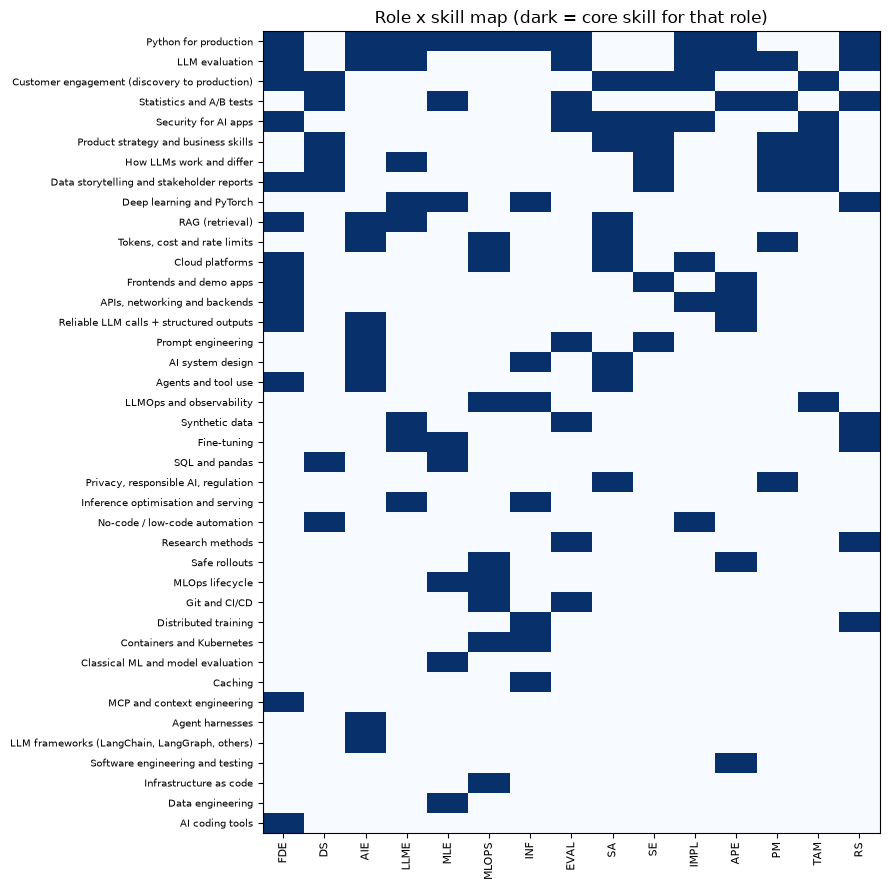

In [13]:
fig, ax = plt.subplots(figsize=(9, 9))
order = shared.index
ax.imshow(matrix.loc[order].values, cmap="Blues", aspect="auto")
ax.set_xticks(range(matrix.shape[1])); ax.set_xticklabels(matrix.columns, rotation=90, fontsize=8)
ax.set_yticks(range(matrix.shape[0])); ax.set_yticklabels(order, fontsize=7)
ax.set_title("Role x skill map (dark = core skill for that role)")
plt.tight_layout(); plt.show()

### 5.2 A personal learning plan from the map

Pick a target role, tick the skills you already have, and let the code list the gaps **in order** with the notebooks to open. Change `TARGET` and `I_ALREADY_KNOW` to make it yours.

In [14]:
def learning_plan(target: str, known: set, hours_per_notebook: float = 2.0) -> pd.DataFrame:
    rows = []
    for skill in ROLE_SKILLS[target]:
        if skill in known:
            continue
        for p in SKILLS[skill]:
            rows.append({"skill": skill, "notebook": p, "est_hours": hours_per_notebook})
    plan = pd.DataFrame(rows)
    return plan

TARGET = "FDE"
I_ALREADY_KNOW = {"Python for production", "Prompt engineering", "RAG (retrieval)"}
plan = learning_plan(TARGET, I_ALREADY_KNOW)
print(f"Gaps for {TARGET}: {plan['skill'].nunique()} skills, {len(plan)} notebooks, about {plan['est_hours'].sum():.0f} hours (rough estimate)")
plan.head(12)

Gaps for FDE: 11 skills, 24 notebooks, about 48 hours (rough estimate)


,skill,notebook,est_hours
0,Customer engagement (discovery to production),28_Applied_AI_and_Forward_Deployed_Engineering/02_forward_deployed_engineeri...,2.0
1,Reliable LLM calls + structured outputs,08_LLM/20_industry_llm_application_patterns.ipynb,2.0
2,Reliable LLM calls + structured outputs,08_LLM/17_structured_outputs.ipynb,2.0
3,Agents and tool use,10_Agents/01_agent_fundamentals.ipynb,2.0
4,Agents and tool use,10_Agents/09_industry_tool_using_agent.ipynb,2.0
5,Agents and tool use,10_Agents/16_agentic_workflow_patterns_and_deep_research.ipynb,2.0
6,MCP and context engineering,10_Agents/05_mcp_and_tools.ipynb,2.0
7,MCP and context engineering,10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb,2.0
8,LLM evaluation,08_LLM/22_llm_evaluation_hands_on.ipynb,2.0
9,LLM evaluation,08_LLM/08_evaluation/01_llm_evaluation.ipynb,2.0


**What just happened?** The plan follows the order in `ROLE_SKILLS`, which puts foundations first. Two hours per notebook is a rough guess; the real time depends on you. Two tips:
- **Learn by building one project, not by finishing every notebook.** Use the plan as a menu, and pull in a notebook when your project needs that skill (section 7).
- **Overlap is your friend.** The top shared skills (Python, LLM evaluation, customer engagement, security) are useful in almost every role, so they are never wasted.

---
## 6. Staying current: a personal learning system

**What it is.** A small, repeatable routine for keeping up with new models, tools and techniques **without** reading everything. AI changes monthly: new model versions, new API features, new agent patterns. A system beats willpower.

**Simple analogy.** A gardener does not watch every plant all day. They have a routine: water daily, prune weekly, replant each season. The routine keeps the garden healthy with little effort.

**How it works: four parts.**

```mermaid
flowchart LR
    I["Inputs<br/>(a few trusted sources)"] --> T["Triage<br/>(score and pick)"]
    T --> TRY["Try it<br/>(on your own small eval set)"]
    TRY --> N["Notes<br/>(one page per idea)"]
    N --> SH["Share<br/>(short post, team demo)"]
    SH -.-> I
```

1. **Inputs: a few trusted sources, in tiers.**
   - *Primary* (most trustworthy): provider release notes and changelogs, model cards and system cards, official docs, papers (arXiv), the code of open-source projects you use.
   - *Practitioner* (high signal): engineering blogs from companies that run AI in production, a handful of newsletters and podcasts by people who build things.
   - *Social* (fast but noisy): community forums and social feeds. Use them to *find* things, then confirm in primary sources.
2. **Triage.** Score each item quickly (how relevant to your work, how credible, how much effort) and read only the top few.
3. **Try it on your own eval set.** Keep a small personal benchmark (20 to 50 tasks from your own work, with expected answers). When a new model or technique appears, run it on your set. Your set tells you more about your work than any public leaderboard.
4. **Notes and sharing.** One short page per idea: what it is, when it helps, a tiny example, links. Share a 5-minute summary with your team once in a while; teaching is the best test of understanding.

**A weekly rhythm that fits in about two hours (example):**

| When | What | Time |
|---|---|---|
| Monday | Skim release notes and your triaged queue | 20 min |
| Wednesday | Read one item properly (paper, long post, docs page) | 45 min |
| Friday | Run one new thing on your personal eval set, write a note | 45 min |
| Monthly | Clean the queue, update your eval set with new real tasks | 30 min |

**When to use it / when not.** Use it always, in small doses. Do not chase every launch: if a change does not move your eval set or your users' problem, note it and move on.

**Check claims before you repeat them.** Ask: who measured this, on what data, against which baseline, and can I reproduce it? (Section 3 of [Research methods](../24_Research_Methods/03_statistical_significance_and_reporting.ipynb) explains why one benchmark number is weak evidence.)

In [15]:
# A reading queue triage scorer. All items are made up. Scores: 1 (low) to 5 (high); effort 1 = quick, 5 = long.
queue = pd.DataFrame([
    ("Release notes: provider adds a new tool-use feature",    "primary",      5, 5, 1),
    ("Paper: new long-context retrieval method",               "primary",      3, 4, 4),
    ("Engineering blog: how a team runs agent evals in CI",    "practitioner", 5, 4, 2),
    ("Social thread: 'this prompt trick is 10x better'",       "social",       3, 1, 1),
    ("Docs page: structured outputs reference",                "primary",      4, 5, 2),
    ("Podcast: deploying agents in a regulated bank",          "practitioner", 4, 3, 3),
    ("Leaderboard update: new model ranks first",              "social",       2, 2, 1),
], columns=["item", "tier", "relevance", "credibility", "effort"])

# Simple rule: value = relevance x credibility, cost = effort. Read the best value-for-effort first.
queue["priority"] = (queue["relevance"] * queue["credibility"] / queue["effort"]).round(2)
print(queue.sort_values("priority", ascending=False).to_string(index=False))

                                               item         tier  relevance  credibility  effort  priority
Release notes: provider adds a new tool-use feature      primary          5            5       1      25.0
Engineering blog: how a team runs agent evals in CI practitioner          5            4       2      10.0
            Docs page: structured outputs reference      primary          4            5       2      10.0
          Leaderboard update: new model ranks first       social          2            2       1       4.0
      Podcast: deploying agents in a regulated bank practitioner          4            3       3       4.0
           Paper: new long-context retrieval method      primary          3            4       4       3.0
   Social thread: 'this prompt trick is 10x better'       social          3            1       1       3.0


In [16]:
# A personal eval log: you record how each model or technique did on YOUR small task set over time.
# This is a stand-in: no real model is called; the scores are invented to show the habit.
personal_eval = pd.DataFrame([
    ("2026-06-02", "model-A (current)",          "baseline prompt",       31, 40, 1.8),
    ("2026-07-14", "model-A (current)",          "+ few-shot examples",   34, 40, 2.1),
    ("2026-08-25", "model-B (new release)",      "baseline prompt",       35, 40, 1.2),
    ("2026-08-25", "model-B (new release)",      "+ few-shot examples",   36, 40, 1.4),
    ("2026-10-06", "model-C small (new)",        "+ few-shot examples",   33, 40, 0.4),
], columns=["date", "model", "technique", "passed", "total", "cost_per_100_tasks_usd"])
personal_eval["pass_rate"] = (personal_eval["passed"] / personal_eval["total"]).round(3)
print(personal_eval.to_string(index=False))
best = personal_eval.sort_values(["pass_rate", "cost_per_100_tasks_usd"], ascending=[False, True]).iloc[0]
print(f"\nBest on my tasks so far: {best['model']} with {best['technique']} ({best['pass_rate']:.0%}).")
print("Note: with only 40 tasks, a difference of 1-2 tasks may be luck; re-run and look at which tasks changed.")

      date                 model           technique  passed  total  cost_per_100_tasks_usd  pass_rate
2026-06-02     model-A (current)     baseline prompt      31     40                     1.8      0.775
2026-07-14     model-A (current) + few-shot examples      34     40                     2.1      0.850
2026-08-25 model-B (new release)     baseline prompt      35     40                     1.2      0.875
2026-08-25 model-B (new release) + few-shot examples      36     40                     1.4      0.900
2026-10-06   model-C small (new) + few-shot examples      33     40                     0.4      0.825

Best on my tasks so far: model-B (new release) with + few-shot examples (90%).
Note: with only 40 tasks, a difference of 1-2 tasks may be luck; re-run and look at which tasks changed.


**What just happened?** Two small tables replace a vague feeling of "falling behind":
- The **queue** puts the release notes and a practitioner post about evals in CI at the top, and the hype thread at the bottom (high relevance, low credibility).
- The **personal eval log** shows a real habit: every new model is tried on the same 40 tasks, with cost recorded next to quality. A small cheap model passing 33/40 at a quarter of the cost can be the right choice for some work.

The [model comparison notebook](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb) and [LLM evaluation hands-on](../08_LLM/22_llm_evaluation_hands_on.ipynb) show how to make such comparisons statistically fair.

---
## 7. Building a portfolio of deployed projects

**What it is.** A **portfolio** is a small set of projects you can show and explain. A **deployed** project is one that **runs somewhere other than your laptop, is used by someone other than you, and is measured**. Those three things are what make a project close to real AI work.

**Simple analogy.** A cook's portfolio is not a list of recipes they have read; it is dishes that real guests ate, with notes on what the guests said.

**How it works: what makes a portfolio project strong.**

| Element | Weak version | Strong version |
|---|---|---|
| Problem | "A chatbot" | "Answers questions about my city's bus timetable for 30 friends who asked for it" |
| Users | Only me | Named group of real users, even if small |
| Baseline | None | "Before: people searched a 40-page PDF; median 3 minutes" |
| Evals | "It works well" | A test set of 60 questions, pass rate before/after each change |
| Deployment | Notebook | A small hosted app or bot, with logs |
| Cost and latency | Not measured | Cost per 100 questions, p95 latency |
| Failure analysis | Hidden | "What went wrong" section with 3 real failures and fixes |
| Write-up | Code only | README with a diagram, results table, and a 2-minute demo video |

**Project ideas that look like deployment work** (use public or synthetic data, never private data you are not allowed to share):
- An assistant for a local club, shop or community group, connected to one real tool (a calendar, a spreadsheet, a ticket form).
- A document Q&A over public government or open-source documentation, with citations and an eval set.
- An "integration" project: a webhook that receives form submissions, classifies them with an LLM and creates a ticket in a free ticketing tool, with retries and idempotency (see [notebook 02, section 9](02_forward_deployed_engineering_in_practice.ipynb)).
- A cost and latency study: the same task on three models, with a decision memo.
- A contribution to an open-source AI tool (docs, a connector, a bug fix). It shows you can work in an unfamiliar codebase, which is what deployment work feels like every day.

**When to use / not.** Fewer, deeper projects beat many shallow ones. Do not invent users or numbers; small and honest is better than big and vague.

In [17]:
# A portfolio README checker: does a project write-up contain the parts that make it convincing?
REQUIRED_PARTS = {
    "problem":      r"\b(problem|why)\b",
    "users":        r"\buser",
    "baseline":     r"\bbaseline|before\b",
    "eval":         r"\beval|test set|pass rate",
    "numbers":      r"\d+(\.\d+)?\s*(%|ms|s\b|usd|\$|minutes|tasks|questions)",
    "deployment":   r"\bdeploy|hosted|running at|live\b",
    "cost_latency": r"\bcost|latency|p95",
    "failures":     r"what went wrong|failure|limitation",
    "diagram":      r"diagram|architecture|mermaid",
}

def check_readme(text: str) -> pd.Series:
    t = text.lower()
    return pd.Series({part: bool(re.search(rx, t)) for part, rx in REQUIRED_PARTS.items()})

readme_weak = "# CityBot\nA chatbot using RAG and a vector database. It works well. Built with Python."
readme_strong = '''# CityBot: bus timetable answers for a cycling club
Problem: 30 club members asked why finding the last bus home takes so long. Users: the club.
Baseline (before): searching a 40-page PDF took a median of 3 minutes.
Eval: a test set of 60 questions; pass rate went from 72% to 90% after adding table-aware chunking.
Deployed as a hosted chat bot; cost is 0.40 usd per 100 questions, p95 latency 1.9 s.
What went wrong: holiday timetables were ignored at first (fixed with a date filter).
Architecture diagram below.'''

report = pd.DataFrame({"weak README": check_readme(readme_weak), "strong README": check_readme(readme_strong)})
print(report.to_string())
print("\nscore:", report.sum().to_dict(), "out of", len(REQUIRED_PARTS))

              weak README  strong README
problem             False           True
users               False           True
baseline            False           True
eval                False           True
numbers             False           True
deployment          False           True
cost_latency        False           True
failures            False           True
diagram             False           True

score: {'weak README': 0, 'strong README': 9} out of 9


**What just happened?** The weak README only names tools. The strong one answers the questions any reviewer, customer or teammate will ask: *for whom, compared with what, how do you know, what does it cost, what broke*. The checker is a crude keyword heuristic; use it as a reminder list, not as a judge.

---
## 8. Telling project stories with STAR

**What it is.** **STAR** is a simple structure for telling a story about your work: **S**ituation (the context), **T**ask (your goal or responsibility), **A**ction (what *you* did, step by step), **R**esult (what happened, with numbers if possible). Many people add **L** for **Learning** (what you would do differently).

**Simple analogy.** A good short news story: where and when, what needed to happen, what was done, and the outcome. No one wants the reporter's whole diary.

**How it works.**
- **Proportions:** a common guide (for example from MIT's career office) is roughly Situation 20%, Task 10%, **Action 60%**, Result 10% plus what you learned. Keep the context short and spend most of the story on what you did.
- **Say "I" for your part.** "We" hides what you did. Mention the team, then be specific about your own actions.
- **Use concrete numbers** for the result, and say how they were measured.
- **Include trade-offs and a decision.** The most useful stories show a choice: what options there were and why you picked one.
- **Prepare 5 to 7 stories** that cover common themes: a hard technical problem, a disagreement, a failure, working with an unclear goal, influencing without authority, a customer under pressure, a time you said no.

**When to use it.** Interviews, performance reviews, project write-ups, and also customer conversations ("here is how a similar team solved this"). When not: a design discussion where people need the details, not a story.

### Worked example 1: a deployment blocked by data

**Weak version.** "We built a RAG system for a customer. There were some data issues but we fixed them and the customer was happy."

**STAR version.**
- **S:** An insurance company wanted an assistant that answers adjusters' policy questions. Two weeks into a six-week pilot, answers were wrong for about a third of the test questions.
- **T:** I was the engineer responsible for answer quality, and the go/no-go review was in four weeks.
- **A:** I sat with two adjusters for a morning and saw that they used the *current* policy wording, while our index mixed in archived versions. I traced the cause to the document export, which had no version field. I agreed with the customer's content team to add an "effective date" field to the export, filtered retrieval on it, and added 40 test questions about recently changed policies to the eval set so this could not silently come back.
- **R:** On the 200-question eval set, correct answers went from 66% to 89%, and the pilot passed its go/no-go review. The test cases for versioned documents became part of our standard eval template.
- **L:** I now ask about document versions in the first discovery meeting.

### Worked example 2: disagreeing with a stakeholder about scope

- **S:** A customer's operations director wanted the assistant to *send* replies to customers automatically from day one.
- **T:** I had to protect the launch date and the customer's reputation, and keep the director's trust.
- **A:** I did not argue in the meeting. I proposed a test: run the assistant in "draft only" mode for two weeks and measure how many drafts agents sent without edits. I showed the results by ticket type and suggested auto-send only where agents accepted over 95% of drafts unchanged.
- **R:** Two of nine ticket types (address changes, delivery-status questions) passed the bar and went to auto-send in week 4. The director agreed with the data-based plan, and there were no customer complaints from auto-sent replies in the first month.
- **L:** Turning a disagreement into a small, measurable experiment is faster than debating.

### Worked example 3: a failure you owned

- **S:** After an upgrade to a newer model, an extraction pipeline I maintained started returning dates in a different format.
- **T:** I owned the pipeline and its release.
- **A:** I rolled back within an hour, wrote a short incident note, and found that our eval set had no examples with non-US date formats. I added 25 such cases, made the output schema strict (one date format), and added the eval suite as a required check before any model upgrade.
- **R:** The upgrade shipped a week later with no format errors on the extended eval set, and later upgrades went through the same gate.
- **L:** Model upgrades are code changes; treat them with the same tests and rollout steps (see [safe rollouts](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)).

In [18]:
# A tiny STAR checker. It looks for: all four parts, a measurable result, the share of "I" vs "we", and length.
def star_feedback(story: dict) -> None:
    text = " ".join(story.get(k, "") for k in "STAR")
    words = re.findall(r"[A-Za-z']+", text)
    i_count = sum(w.lower() in {"i", "i'm", "i've", "my", "me"} for w in words)
    we_count = sum(w.lower() in {"we", "our", "us", "we've"} for w in words)
    action_share = len(story.get("A", "").split()) / max(1, len(words))
    has_number = bool(re.search(r"\d", story.get("R", "")))
    print(f"parts present: {[k for k in 'STAR' if story.get(k)]}")
    print(f"words: {len(words)} | action share: {action_share:.0%} (aim ~60%) | 'I' words: {i_count} vs 'we' words: {we_count}")
    print("result has a number:", has_number)
    tips = []
    if any(not story.get(k) for k in "STAR"): tips.append("add the missing part(s)")
    if action_share < 0.4: tips.append("spend more of the story on what you did (the Action)")
    if we_count > i_count: tips.append("say 'I' for your own actions")
    if not has_number: tips.append("give a measurable result and how it was measured")
    print("tips:", tips or ["looks well structured"])

weak = {"S": "We built a RAG system for a customer.", "T": "", "A": "There were some data issues but we fixed them.", "R": "The customer was happy."}
strong = {
    "S": "An insurance company wanted an assistant for policy questions; answers were wrong for a third of test questions two weeks into a pilot.",
    "T": "I was responsible for answer quality with a go/no-go review in four weeks.",
    "A": ("I sat with two adjusters and saw they used current policy wording while our index mixed archived versions. "
          "I traced the cause to the export, agreed a new effective-date field with the content team, filtered retrieval on it, "
          "and added 40 test questions on recently changed policies to the eval set."),
    "R": "Correct answers on the 200-question eval set rose from 66% to 89% and the pilot passed review.",
}
print("--- weak story"); star_feedback(weak)
print("\n--- strong story"); star_feedback(strong)

--- weak story
parts present: ['S', 'A', 'R']
words: 21 | action share: 43% (aim ~60%) | 'I' words: 0 vs 'we' words: 2
result has a number: False
tips: ['add the missing part(s)', "say 'I' for your own actions", 'give a measurable result and how it was measured']

--- strong story
parts present: ['S', 'T', 'A', 'R']
words: 104 | action share: 49% (aim ~60%) | 'I' words: 3 vs 'we' words: 1
result has a number: True
tips: ['looks well structured']


**What just happened?** The checker shows in numbers what the reader feels: the weak story has no task, no numbers, and only "we". The strong story spends most of its words on actions and ends with a measured result. Like the README checker, it is a heuristic to help you revise, not a grade.

**A story bank.** Write each story once in this format and keep it in a document; update the numbers when projects end. Tag each story with the themes it fits so you can find the right one quickly.

In [19]:
story_bank = pd.DataFrame([
    ("Versioned policy docs broke RAG", {"hard technical problem", "customer under pressure", "data"}),
    ("Draft-only before auto-send",     {"disagreement", "influence without authority", "customer"}),
    ("Date format after model upgrade", {"failure", "ownership", "quality"}),
], columns=["story", "themes"])

def find_story(theme: str) -> list:
    return [s for s, t in zip(story_bank["story"], story_bank["themes"]) if theme in t]

for theme in ["failure", "disagreement", "customer under pressure", "said no"]:
    print(f"{theme:>26}: {find_story(theme) or 'no story yet: write one'}")

                   failure: ['Date format after model upgrade']
              disagreement: ['Draft-only before auto-send']
   customer under pressure: ['Versioned policy docs broke RAG']
                   said no: no story yet: write one


---
## 9. Recap

| Topic | Key idea | Where to go deeper |
|---|---|---|
| Role names | Titles vary; read a role by who it serves, how close to the model it is, and what it produces | Section 1-3 |
| FDE and deployment strategist | Engineers and strategists embedded with customers, owning the path from discovery to production | [Notebook 02](02_forward_deployed_engineering_in_practice.ipynb) |
| Builder roles | Applied AI, LLM, ML and AI product engineers build the features and models | [08_LLM](../08_LLM/), [10_Agents](../10_Agents/) |
| Platform roles | MLOps/LLMOps builds the path to production; inference engineers make serving fast and cheap | [15_MLOps](../15_MLOps/), [08_LLM/13](../08_LLM/13_inference_optimization.ipynb) |
| Evals | Quality is measured by test sets and graders that look like real use; everyone shares it | [08_LLM/22](../08_LLM/22_llm_evaluation_hands_on.ipynb) |
| Commercial and product roles | Sales engineers win the technical evaluation; PMs decide what to build; TAMs keep value flowing | [Notebook 03](03_ai_product_strategy_and_business_skills.ipynb) |
| RACI | One Accountable per activity, at least one Responsible; the customer owns success criteria | Section 4 |
| Skills maps | Shared skills first (Python, evals, customer engagement, security), then specialist ones | Section 5 |
| Staying current | Few trusted sources, triage, try on your own eval set, short notes | Section 6 |
| Portfolio | Deployed = runs elsewhere, used by others, measured; show baselines and failures | Section 7 |
| STAR | Short S and T, long A in "I", measurable R, add a Learning | Section 8 |

## Interview questions

1. **What does a forward deployed engineer do that a solutions architect usually does not?**
   The FDE builds and ships the production solution inside the customer's environment (code, integrations, evals, runbooks). The architect designs how it should fit and guides the build, usually writing less production code.
2. **How is an implementation engineer different from an FDE?**
   Implementation is mostly configuring and connecting a standard product in a repeatable way. FDE work is more custom: new integrations, new agent logic, and solving problems the product does not yet solve.
3. **What is a RACI matrix and what are its two key rules?**
   A table of activities x roles with Responsible, Accountable, Consulted, Informed. Exactly one A per activity, and at least one R.
4. **Who should be accountable for the success criteria of a deployment, and why?**
   The customer (their sponsor). They own the business outcome; the vendor helps define and measure it, but the customer must agree what "good" means.
5. **MLOps engineer vs inference engineer?**
   MLOps owns the path from code to production (pipelines, registry, CI/CD, observability). Inference owns the speed, cost and reliability of the serving engine itself.
6. **Why do evals belong to everyone, even when there is an evals engineer?**
   Every change (prompt, model, tool, data) can break quality. Whoever makes a change must run and extend the evals; the evals engineer makes this easy and trustworthy.
7. **How do you keep up with new models without reading everything?**
   A few primary and practitioner sources, quick triage, and testing new things on a personal eval set from your own work; keep short notes.
8. **What makes a portfolio project "deployed"?**
   It runs outside your laptop, real people use it, and you measure it (baseline, eval results, cost, latency), with honest failure analysis.
9. **Tell me about a time you disagreed with a customer.** (Practise with STAR.)
   Keep S and T short, describe your actions in "I", end with a measured result and what you learned. Worked example 2 in section 8 shows one shape.
10. **What is the field feedback loop and why does it matter?**
    Learnings from customer deployments go back to product and research so that one customer's fix becomes everyone's feature; without it, every deployment stays custom work.

## Further reading

- Palantir blog, "Dev versus Delta: Demystifying engineering roles at Palantir" (blog.palantir.com), the original description of product engineers vs forward deployed engineers.
- Barry McCardel, "FDE culture" (barry.ooo/posts/fde-culture), by a former Palantir deployment strategist.
- Marty Cagan, "Forward Deployed Engineers" (svpg.com, 2025) and Gergely Orosz, "Forward deployed engineers" (The Pragmatic Engineer newsletter, 2025), including how AI companies run FDE teams.
- Nabeel S. Qureshi, "Reflections on Palantir" (2024 essay), for a first-hand view of the forward deployed model.
- Chip Huyen, *AI Engineering: Building Applications with Foundation Models* (O'Reilly, 2025), especially the chapters on evaluation and on the AI engineering stack.
- Hamel Husain, "Your AI Product Needs Evals" (hamel.dev, 2024).
- Eugene Yan, "Patterns for Building LLM-based Systems and Products" (eugeneyan.com, 2023).
- RACI: the Project Management Institute's *PMBOK Guide* describes the responsibility assignment matrix (RAM), of which RACI is the common form.
- MIT Career Advising & Professional Development, "The STAR method for behavioral interviews" (capd.mit.edu).
- In this repo: [Research methods](../24_Research_Methods/README.md) (how to make claims others can check), [Building and shipping an AI feature](../23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb), [AI system design](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb).
- Next: [02 Forward deployed engineering in practice](02_forward_deployed_engineering_in_practice.ipynb) and [03 AI product strategy and business skills](03_ai_product_strategy_and_business_skills.ipynb).